### Testing functionalities

In [1]:
from data_collection.data_adapters import DatabentoGenericAdapter
from dotenv import load_dotenv
from pathlib import Path
import os
import polars as pl
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
load_dotenv()

CACHE_DIR = Path.cwd().resolve().parents[1] / "data" / "dbn_cache" / "generic"
adapter = DatabentoGenericAdapter(os.getenv("DATABENTO-API-KEY"), CACHE_DIR)

# Clear the cache if needed
# adapter.clear_cache()

# Imbalance
df_imbalance, map_imbalance = await adapter.get_data(
    tickers=["AMZN"],
    start_date="2026-04-19",
    end_date="2026-05-19",
    dataset="XNAS.ITCH",
    schema="Imbalance"
)
map_imbalance = {v: k for k,v in map_imbalance.items()}
df_imbalance = df_imbalance.filter(pl.col('ts_event').dt.time().is_between(pl.time(19,50), pl.time(20,00))).sort('ts_event')

# 1s Bars
df_bars, map_bars = await adapter.get_data(
    tickers=["AMZN"],
    start_date="2026-04-19",
    end_date="2026-05-19",
    dataset="XNAS.ITCH",
    schema="ohlcv-1s"
)
map_bars = {v: k for k,v in map_bars.items()}
df_bars = df_bars.filter(pl.col('ts_event').dt.time().is_between(pl.time(13,30), pl.time(20,00))).sort('ts_event')

# Statistics (for auction price)
df_stats, map_stats = await adapter.get_data(
    tickers=["AMZN"],
    start_date="2026-04-19",
    end_date="2026-05-19",
    dataset="XNAS.ITCH",
    schema="statistics"
)
map_stats = {v: k for k,v in map_stats.items()}
# df_stats = df_stats.with_columns(pl.col('ts_event').dt.convert_time_zone("UTC"))

[GenericAdapter] Parquet cache hit: 09a704dcc7d1071e299eb6af360b5c58.parquet
[GenericAdapter] Parquet cache hit: 23cd3cce979ab29796e47e1468bf5553.parquet
[GenericAdapter] Parquet cache hit: 1f844be1ec87fbd0d0389d602155c8e5.parquet


In [2]:
df_stats.filter(pl.col('stat_type') == 11).sort('ts_event')

ts_recv,ts_event,rtype,publisher_id,instrument_id,ts_ref,price,quantity,sequence,ts_in_delta,stat_type,channel_id,update_action,stat_flags,symbol
"datetime[ns, UTC]","datetime[ns, UTC]",u8,u16,u32,"datetime[ns, UTC]",f64,i32,u32,i32,u16,u16,u8,u8,str
2026-04-20 20:00:00.004103221 UTC,2026-04-20 20:00:00.003921175 UTC,24,2,853,null,248.28,4665094,759989169,182046,11,0,1,0,"""AMZN"""
2026-04-21 20:00:00.510661872 UTC,2026-04-21 20:00:00.510474868 UTC,24,2,853,null,249.91,3960917,950226256,187004,11,0,1,0,"""AMZN"""
2026-04-22 20:00:00.126288622 UTC,2026-04-22 20:00:00.126106418 UTC,24,2,853,null,255.36,4856307,709169804,182204,11,0,1,0,"""AMZN"""
2026-04-23 20:00:00.118523729 UTC,2026-04-23 20:00:00.118349658 UTC,24,2,853,null,255.08,5119398,961080164,174071,11,0,1,0,"""AMZN"""
2026-04-24 20:00:00.182973431 UTC,2026-04-24 20:00:00.182792694 UTC,24,2,853,null,263.99,4579772,802844825,180737,11,0,1,0,"""AMZN"""
…,…,…,…,…,…,…,…,…,…,…,…,…,…,…
2026-05-12 20:00:00.411460411 UTC,2026-05-12 20:00:00.411270617 UTC,24,2,853,null,265.82,5596087,994837444,189794,11,0,1,0,"""AMZN"""
2026-05-13 20:00:00.711405969 UTC,2026-05-13 20:00:00.711235474 UTC,24,2,853,null,270.13,5535611,841142083,170495,11,0,1,0,"""AMZN"""
2026-05-14 20:00:00.464433940 UTC,2026-05-14 20:00:00.464253707 UTC,24,2,853,null,267.22,3483233,867972276,180233,11,0,1,0,"""AMZN"""


In [3]:
df_imbalance = (
    df_imbalance
    .with_columns(pl.col("ts_event").dt.truncate("1s"))
    .upsample(time_column="ts_event", every="1s")
    .fill_null(strategy='forward')
    .select(["ts_event", "ref_price", "side", "total_imbalance_qty", "cont_book_clr_price", "auct_interest_clr_price"])
    .sort('ts_event')
)
df_imbalance

ts_event,ref_price,side,total_imbalance_qty,cont_book_clr_price,auct_interest_clr_price
"datetime[ns, UTC]",f64,str,u32,f64,f64
2026-04-20 19:50:00 UTC,248.34,"""A""",404589,0.0,0.0
2026-04-20 19:50:01 UTC,248.34,"""A""",404589,0.0,0.0
2026-04-20 19:50:02 UTC,248.34,"""A""",404589,0.0,0.0
2026-04-20 19:50:03 UTC,248.34,"""A""",404589,0.0,0.0
2026-04-20 19:50:04 UTC,248.34,"""A""",404589,0.0,0.0
…,…,…,…,…,…
2026-05-18 19:59:55 UTC,264.76,"""A""",40223,264.64,264.64
2026-05-18 19:59:56 UTC,264.83,"""A""",45648,264.64,264.64
2026-05-18 19:59:57 UTC,264.82,"""A""",40660,264.64,264.64


In [75]:
data = df_bars.select(['ts_event', 'close', 'volume']).join(df_imbalance, on='ts_event', how='left', coalesce=True).sort('ts_event')
data

ts_event,close,volume,ref_price,side,total_imbalance_qty,cont_book_clr_price,auct_interest_clr_price
"datetime[ns, UTC]",f64,u64,f64,str,u32,f64,f64
2026-04-20 13:30:00 UTC,249.25,705653,null,null,null,null,null
2026-04-20 13:30:01 UTC,249.26,10998,null,null,null,null,null
2026-04-20 13:30:02 UTC,249.57,23728,null,null,null,null,null
2026-04-20 13:30:03 UTC,249.78,6099,null,null,null,null,null
2026-04-20 13:30:04 UTC,249.86,8292,null,null,null,null,null
…,…,…,…,…,…,…,…
2026-05-18 19:59:56 UTC,264.82,5864,264.83,"""A""",45648,264.64,264.64
2026-05-18 19:59:57 UTC,264.81,5275,264.82,"""A""",40660,264.64,264.64
2026-05-18 19:59:58 UTC,264.85,48785,264.82,"""A""",37277,264.67,264.64


In [77]:
session_dollar_volume = (data
 .filter(pl.col('ts_event').dt.time().is_between(pl.time(13,30), pl.time(19,50)))
 .group_by_dynamic(
     index_column='ts_event',
     every='1d'
 ).agg(
     (pl.col('volume') * pl.col("close")).sum() #approximated using seconds closing prices
 )
).rename({"volume": "session_dollar_volume", "ts_event": "date"})

data = (
    data
    # day key (00:00:00 UTC) to match session_dollar_volume's ts_event
    .with_columns(pl.col("ts_event").dt.truncate("1d").alias("date"))
    .join(
        session_dollar_volume,
        on="date",
        how="left",
    )
    .with_columns(
        (
            pl.when(pl.col("side") == "A").then(-1.0)
            .when(pl.col("side") == "B").then(1.0)
            .otherwise(0.0)
            * pl.col("total_imbalance_qty") * pl.col("close")
            / pl.col("session_dollar_volume")
        ).alias("qty_signal")
    )
    .drop("date")
    .sort("ts_event")
)

data = data.fill_null(0)
data

ts_event,close,volume,ref_price,side,total_imbalance_qty,cont_book_clr_price,auct_interest_clr_price,session_dollar_volume,qty_signal,session_dollar_volume_right
"datetime[ns, UTC]",f64,u64,f64,str,u32,f64,f64,f64,f64,f64
2026-04-20 13:30:00 UTC,249.25,705653,0.0,null,0,0.0,0.0,1.3228e9,0.0,1.3228e9
2026-04-20 13:30:01 UTC,249.26,10998,0.0,null,0,0.0,0.0,1.3228e9,0.0,1.3228e9
2026-04-20 13:30:02 UTC,249.57,23728,0.0,null,0,0.0,0.0,1.3228e9,0.0,1.3228e9
2026-04-20 13:30:03 UTC,249.78,6099,0.0,null,0,0.0,0.0,1.3228e9,0.0,1.3228e9
2026-04-20 13:30:04 UTC,249.86,8292,0.0,null,0,0.0,0.0,1.3228e9,0.0,1.3228e9
…,…,…,…,…,…,…,…,…,…,…
2026-05-18 19:59:56 UTC,264.82,5864,264.83,"""A""",45648,264.64,264.64,1.4951e9,-0.008085,1.4951e9
2026-05-18 19:59:57 UTC,264.81,5275,264.82,"""A""",40660,264.64,264.64,1.4951e9,-0.007202,1.4951e9
2026-05-18 19:59:58 UTC,264.85,48785,264.82,"""A""",37277,264.67,264.64,1.4951e9,-0.006603,1.4951e9


Need to get the real close auction execution prices from the statistics df into the data df.

In [78]:
# Overwrite the 20:00:00 bar's close/volume with the real close-auction execution
# price/quantity from df_stats (stat_type 11 = closing price, one row per date).
df_close_auction = (
    df_stats
    .filter(pl.col('stat_type') == 11)
    .select(
        pl.col('ts_event').dt.date().alias('date'),
        pl.col('price').alias('auction_price'),
        pl.col('quantity').cast(pl.UInt64).alias('auction_qty'),
    )
)

data = (
    data
    .with_columns(pl.col('ts_event').dt.date().alias('date'))
    .join(df_close_auction, on='date', how='left')
    .with_columns(
        close=pl.when(pl.col('ts_event').dt.time() == pl.time(20, 0, 0))
                .then(pl.col('auction_price'))
                .otherwise(pl.col('close')),
        volume=pl.when(pl.col('ts_event').dt.time() == pl.time(20, 0, 0))
                .then(pl.col('auction_qty'))
                .otherwise(pl.col('volume')),
    )
    .drop(['date', 'auction_price', 'auction_qty'])
    .sort('ts_event')
)

# Sanity check: the 20:00:00 rows now carry the auction price/qty
data.filter(pl.col('ts_event').dt.time() == pl.time(20, 0, 0))


ts_event,close,volume,ref_price,side,total_imbalance_qty,cont_book_clr_price,auct_interest_clr_price,session_dollar_volume,qty_signal,session_dollar_volume_right
"datetime[ns, UTC]",f64,u64,f64,str,u32,f64,f64,f64,f64,f64
2026-04-20 20:00:00 UTC,248.28,4665094,248.34,"""A""",26086,248.3,248.3,1.3228e9,-0.004899,1.3228e9
2026-04-21 20:00:00 UTC,249.91,3960917,249.91,"""A""",23237,249.88,249.88,1.7977e9,-0.00323,1.7977e9
2026-04-22 20:00:00 UTC,255.36,4856307,255.33,"""B""",47900,255.43,255.43,1.3084e9,0.009347,1.3084e9
2026-04-23 20:00:00 UTC,255.08,5119398,255.04,"""A""",15616,255.01,255.0,1.6513e9,-0.002412,1.6513e9
2026-04-24 20:00:00 UTC,263.99,4579772,263.94,"""B""",290521,263.99,263.99,2.1173e9,0.03623,2.1173e9
…,…,…,…,…,…,…,…,…,…,…
2026-05-12 20:00:00 UTC,265.82,5596087,265.82,"""N""",0,265.82,265.82,1.3741e9,0.0,1.3741e9
2026-05-13 20:00:00 UTC,270.13,5535611,270.17,"""N""",0,270.17,270.17,1.4809e9,0.0,1.4809e9
2026-05-14 20:00:00 UTC,267.22,3483233,267.24,"""A""",14576,267.16,267.13,1.1743e9,-0.003317,1.1743e9


In [79]:
df_stats.filter(pl.col("stat_type") == 11).sort("ts_event")

ts_recv,ts_event,rtype,publisher_id,instrument_id,ts_ref,price,quantity,sequence,ts_in_delta,stat_type,channel_id,update_action,stat_flags,symbol
"datetime[ns, UTC]","datetime[ns, UTC]",u8,u16,u32,"datetime[ns, UTC]",f64,i32,u32,i32,u16,u16,u8,u8,str
2026-04-20 20:00:00.004103221 UTC,2026-04-20 20:00:00.003921175 UTC,24,2,853,null,248.28,4665094,759989169,182046,11,0,1,0,"""AMZN"""
2026-04-21 20:00:00.510661872 UTC,2026-04-21 20:00:00.510474868 UTC,24,2,853,null,249.91,3960917,950226256,187004,11,0,1,0,"""AMZN"""
2026-04-22 20:00:00.126288622 UTC,2026-04-22 20:00:00.126106418 UTC,24,2,853,null,255.36,4856307,709169804,182204,11,0,1,0,"""AMZN"""
2026-04-23 20:00:00.118523729 UTC,2026-04-23 20:00:00.118349658 UTC,24,2,853,null,255.08,5119398,961080164,174071,11,0,1,0,"""AMZN"""
2026-04-24 20:00:00.182973431 UTC,2026-04-24 20:00:00.182792694 UTC,24,2,853,null,263.99,4579772,802844825,180737,11,0,1,0,"""AMZN"""
…,…,…,…,…,…,…,…,…,…,…,…,…,…,…
2026-05-12 20:00:00.411460411 UTC,2026-05-12 20:00:00.411270617 UTC,24,2,853,null,265.82,5596087,994837444,189794,11,0,1,0,"""AMZN"""
2026-05-13 20:00:00.711405969 UTC,2026-05-13 20:00:00.711235474 UTC,24,2,853,null,270.13,5535611,841142083,170495,11,0,1,0,"""AMZN"""
2026-05-14 20:00:00.464433940 UTC,2026-05-14 20:00:00.464253707 UTC,24,2,853,null,267.22,3483233,867972276,180233,11,0,1,0,"""AMZN"""


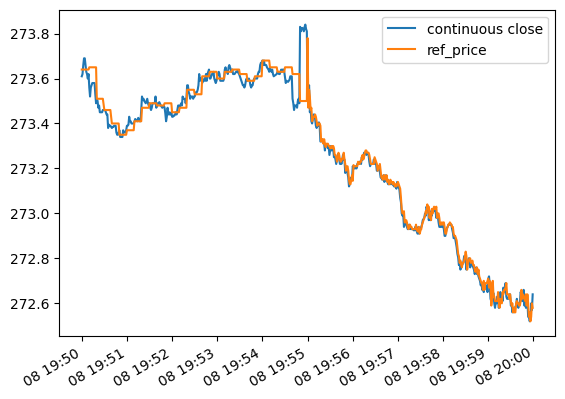

Final Closing Auction Price: 272.64


In [88]:
date = pl.date(2026,5,8)
plot_data = data.filter(pl.col('ts_event').dt.time().is_between(pl.time(19,50), pl.time(19,59,59)),
                        pl.col('ts_event').dt.date() == date)

plt.plot(plot_data.select('ts_event'), plot_data.select('close'),
         label='continuous close')

plt.plot(plot_data.select('ts_event'), plot_data.select('ref_price'),
         label='ref_price')

plt.legend()
plt.gcf().autofmt_xdate()
plt.show()

print(f"Final Closing Auction Price: {plot_data['close'][-1]}")

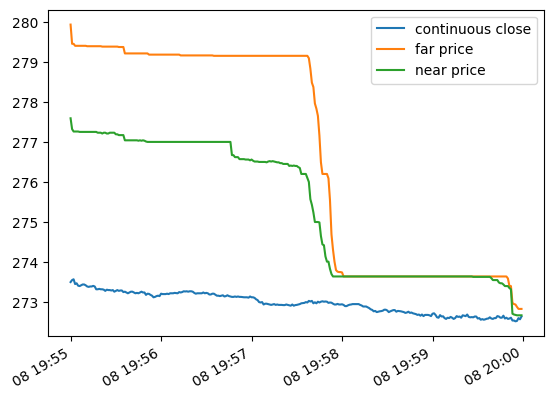

In [93]:
plot_data = data.filter(pl.col('ts_event').dt.time().is_between(pl.time(19,55,00), pl.time(19,59,59)),
                        pl.col('ts_event').dt.date() == date)

plt.plot(plot_data.select('ts_event'), plot_data.select('close'),
         label='continuous close')

plt.plot(plot_data.select('ts_event'), plot_data.select('auct_interest_clr_price'),
         label='far price')

plt.plot(plot_data.select('ts_event'), plot_data.select('cont_book_clr_price'),
         label='near price')
# 
plt.legend()
plt.gcf().autofmt_xdate()
plt.show()

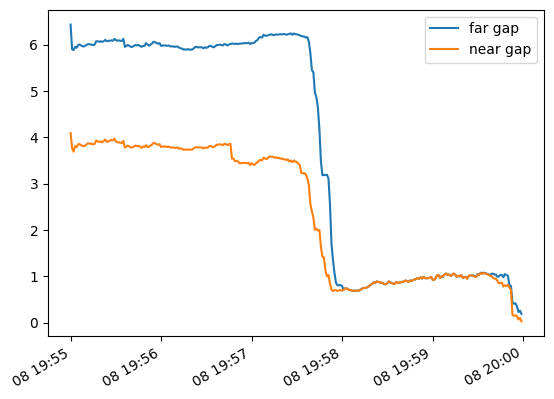

In [94]:
plot_data = data.filter(pl.col('ts_event').dt.time().is_between(pl.time(19,55), pl.time(19,59,59)),
                        pl.col('ts_event').dt.date() == date)

plt.plot(plot_data.select('ts_event'), plot_data.select('auct_interest_clr_price') - plot_data.select('close'),
         label='far gap')
plt.plot(plot_data.select('ts_event'), plot_data.select('cont_book_clr_price') - plot_data.select('close'),
         label='near gap')

plt.legend()
plt.gcf().autofmt_xdate()
plt.show()

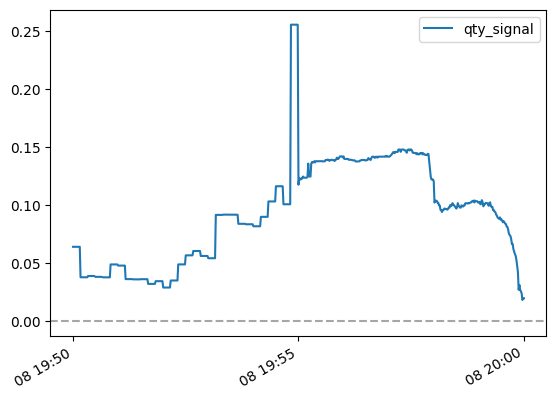

In [95]:
plot_data = data.filter(pl.col('ts_event').dt.time().is_between(pl.time(19,50), pl.time(20,00,00)),
                        pl.col('ts_event').dt.date() == date)
plt.plot(plot_data.select('ts_event'), plot_data.select('qty_signal'),
         label='qty_signal')
plt.axhline(y=0, color='gray', linewidth='1.5', linestyle='--', alpha=0.7)

plt.legend()
plt.gcf().autofmt_xdate()
plt.show()